In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
muestras = 1000
theta0_r = 10.0
theta1_r = 2.5
ruido_scale = 45.0

In [15]:
np.random.seed(67)
x = np.random.uniform(10, 100, muestras)
ruido = np.random.normal(0.0, ruido_scale, muestras)
y = theta0_r + theta1_r * x + ruido
print(x)
print("")
print(y)

[59.12662869 87.29709495 71.73033279 39.84326389 15.39981366 44.76500029
 29.18348728 93.92559851 75.0536469  14.2205776  83.91797644 63.26825494
 32.68643576 38.35690214 26.905422   41.52879163 33.15185307 11.00027038
 46.86296589 47.10290064 13.88698938 95.95079141 45.79095563 57.66925507
 30.95316214 37.77444573 59.67800553 73.76280661 95.80820979 64.17323265
 46.2026413  41.94371796 83.27471413 36.78776733 59.01528925 96.67739944
 26.50559279 75.51976044 75.99160584 14.15259807 97.26277544 43.34891889
 73.62498138 34.65376314 32.41405584 37.4475142  22.49667897 97.7603369
 10.75707139 90.50246206 41.87837622 93.43318021 46.04389009 52.16060714
 50.27024898 91.75819355 67.80666486 31.58235527 70.87051749 48.62640917
 30.25546146 23.66519873 50.81966915 83.97080925 67.41530462 99.74488238
 57.4181275  32.04514624 12.55992891 72.15960181 36.67758736 79.29911743
 26.89090766 51.76052487 11.11721903 24.08895711 25.16487338 31.38800083
 66.61409246 25.05317413 42.29149469 82.10087836 81.

cm barba maago
x = [
    54, 58, 41, 92, 32, 27, 33, 15, 53, 98,
    35, 78, 32, 17, 24, 55, 29, 85, 35, 45,
    28, 59, 37, 51, 28, 53, 30, 25, 36, 21,
    64, 52, 86, 39, 21, 20, 97, 24, 70, 25,
    40, 38, 33, 28, 33, 46, 74, 56, 58, 26,
    25, 75, 18, 72, 35, 42, 42, 67, 44, 22,
    54, 26, 71, 27, 25, 79, 47, 29, 43, 25,
    42, 16, 24, 49, 31, 25, 17, 28, 30, 43,
    66, 41, 84, 22, 74, 55, 84, 14, 65, 45,
    52, 32, 89, 44, 90, 88, 77, 20, 53, 28
]

# Dannio magico mago
y = [
    289, 408, 198, 451, 102, 348, 240, 429, 155, 485,
    115, 439, 321, 222, 378, 278, 181, 418, 472, 230,
    130, 355, 258, 412, 310, 201, 448, 162, 390,  95,
    332, 284, 435, 225, 366, 141, 480, 251, 403, 208,
    318, 175, 465, 263, 375, 122, 422, 301, 219, 344,
    148, 442, 275, 392, 187, 468, 239, 351, 110, 416,
    312, 212, 458, 169, 382, 269, 433, 134, 330, 292,
    192, 477, 245, 401, 143, 427, 306, 221, 360, 108,
    339, 253, 460, 167, 397, 287, 444, 128, 323, 233,
    371, 199, 491, 156, 407, 261, 347,  92, 420, 309
]


In [4]:
def quad_err(t0, t1):
    err = 0.0
    for xi, yi in zip(x, y):
        inf = t0 + t1 * xi
        err += (yi - inf) ** 2
    return err

In [5]:
def get_init_bounds(x_vals, y_vals):
    x_arr, y_arr = np.array(x_vals), np.array(y_vals)

    # y = mx + b -> m_est = frac{y_max - y_min}{x_max - x_min}
    range_x = np.ptp(x_arr)
    range_y = np.ptp(y_arr)
    m_est = range_y / range_x

    t1_low, t1_high = -2 * m_est, 2 * m_est

    # y = t0 + t1 * x -> t0 = y - t1 * x
    mean_x, mean_y = np.mean(x_arr), np.mean(y_arr)
    t0_est1 = mean_y - t1_low * mean_x
    t0_est2 = mean_y - t1_high * mean_x

    t0_low = min(t0_est1, t0_est2)
    t0_high = max(t0_est1, t0_est2)

    t0_margin = (t0_high - t0_low) * 0.5
    t0_low -= t0_margin
    t0_high += t0_margin

    return t0_low, t0_high, t1_low, t1_high

In [6]:
def get_best_t(t0_low, t0_high, t1_low, t1_high, steps):
    best_t0, best_t1 = 0.0, 0.0
    min_error = float('inf')

    range_t0 = [t0_low + i * (t0_high - t0_low) / steps for i in range(steps)]
    range_t1 = [t1_low + i * (t1_high - t1_low) / steps for i in range(steps)]

    for t0_test in range_t0:
        for t1_test in range_t1:
            err = quad_err(t0_test, t1_test)
            if err < min_error:
                min_error = err
                best_t0 = t0_test
                best_t1 = t1_test

    return best_t0, best_t1

In [7]:
def search_until_best(x_vals, y_vals, phases=3, steps=100):
    t0_low, t0_high, t1_low, t1_high = get_init_bounds(x_vals, y_vals)

    best_t0, best_t1 = 0.0, 0.0
    for _ in range(phases):
        best_t0, best_t1 = get_best_t(t0_low, t0_high, t1_low, t1_high, steps)

        t0_radius = (t0_high - t0_low) * 0.1
        t1_radius = (t1_high - t1_low) * 0.1

        t0_low, t0_high = best_t0 - t0_radius, best_t0 + t0_radius
        t1_low, t1_high = best_t1 - t1_radius, best_t1 + t1_radius

    return best_t0, best_t1

In [8]:
theta0, theta1 = search_until_best(x, y, phases=3, steps=200)

In [9]:
def pred_dmg(cm_barba) -> float:
    return theta0 + theta1 * cm_barba

In [16]:
cm = int(input("Tamannio de la barba del mago: "))
infer = pred_dmg(cm)

Tamannio de la barba del mago:  60


In [17]:
print(f"Theta 0 = {theta0:.2f}") 
print(f"Theta 1 = {theta1:.2f}")
print(f"Dannio inferido: {infer:.2f}")

Theta 0 = 10.57
Theta 1 = 2.47
Dannio inferido: 158.62


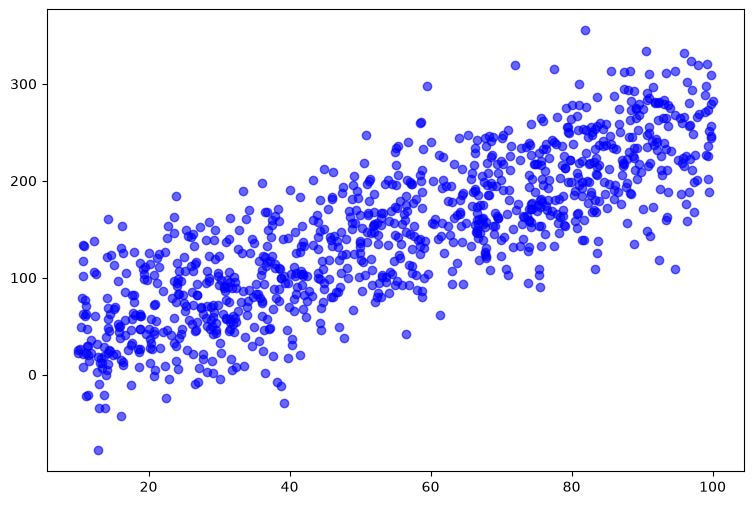

In [18]:
plt.figure(figsize=(9,6))
plt.scatter(x, y, color='blue', alpha=0.6, label='Datos reales (Barba vs Dannio)')

In [19]:
x_line = np.linspace(min(x), max(x), 200)
y_line = theta0 + theta1 * x_line

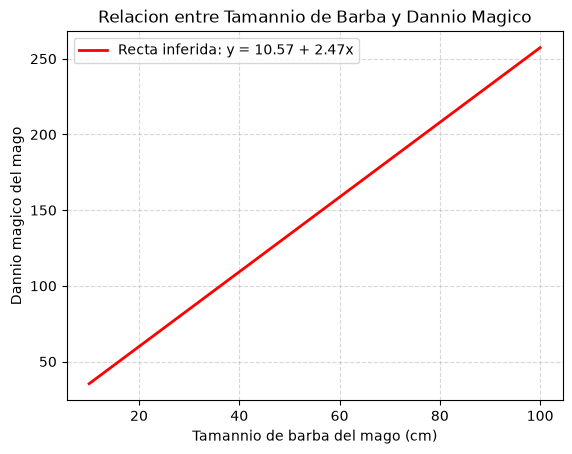

In [14]:
plt.plot(x_line, y_line, color='red', linewidth=2, label=f'Recta inferida: y = {theta0:.2f} + {theta1:.2f}x')
plt.title('Relacion entre Tamannio de Barba y Dannio Magico')
plt.xlabel('Tamannio de barba del mago (cm)')
plt.ylabel('Dannio magico del mago')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()